# Prototype Conformer Tabular Medical Check-up

**Tujuan notebook:** mencoba pipeline Conformer pada **dataset yang benar** untuk demo/prototype.

> Dataset ini masih dataset lama untuk eksperimen. Target 4 kelas digunakan hanya untuk mencoba pipeline.

Target:
- `0` = Sehat / Tidak Ada Indikasi
- `1` = Jantung dan Pembuluh Darah
- `2` = Spes. Penyakit Dalam
- `3` = Spes. Paru-Paru

Flow notebook:

```text
NOTE 2.1  Load & Audit
      ↓
NOTE 2.2  Define Feature & Target
      ↓
NOTE 2.3  Train/Validation/Test Split
      ↓
NOTE 2.4  Scaling
      ↓
NOTE 2.5  Tabular Tokenization
      ↓
NOTE 2.6  Conformer Block
      ↓
NOTE 2.7  Forward Pass
      ↓
NOTE 2.8  Training
      ↓
NOTE 2.9  Evaluation
      ↓
NOTE 2.10 Single Patient Prediction
```

Notebook ini dibuat lebih stabil daripada prototype sebelumnya: dataset sudah numerik/bersih, preprocessing tidak melakukan mapping kategorikal ulang, model menggunakan **pre-norm + residual yang stabil**, gradient clipping, dan learning rate konservatif.

## 1. Import Library & Load Dataset

In [1]:
import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch :", torch.__version__)
print("Device  :", device)


PyTorch : 2.11.0+cpu
Device  : cpu


In [3]:
#DATA_PATH = "merge_DocLab_hybrid.csv"
#DATA_PATH = "merge_DocLab_balanced.csv"
DATA_PATH = "merge_DocLab_WithLab_imputed.csv"

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.head(5)

Shape: (4160, 14)


,JENIS_KELAMIN,UMUR_TAHUN,cholesterol total,creatinin,fbs,rbs,hgb,lymfosit%,mch,mchc,mcv,ureum,wbc,NM_UNIT
0,0,38.0,193.7,1.1,101.0,138.0,12.4,15.6,28.8,32.0,511.0,24.0,11.4,1.0
1,1,60.0,221.9,1.1,134.0,188.0,11.7,29.0,29.6,32.8,90.3,45.4,7.3,2.0
2,0,79.0,178.2,2.2,145.9,194.0,9.8,24.6,27.5,32.3,85.0,67.0,7.5,2.0
3,1,67.0,208.7,1.2,160.1,154.0,9.8,25.3,27.7,32.2,85.7,45.6,7.3,2.0
4,0,68.0,183.7,2.1,110.2,477.0,10.3,15.4,28.3,33.3,85.0,75.0,17.1,2.0


In [4]:
print("Data types:")
df.dtypes

print("\nMissing values:")
df.isna().sum()

print("\nDuplicated rows:", df.duplicated().sum())

print("\nTarget distribution:")
df["NM_UNIT"].value_counts().sort_index()

Data types:

Missing values:

Duplicated rows: 410

Target distribution:


,count
NM_UNIT,
0.0,3539
1.0,52
2.0,559
3.0,10


## 2. Target & Feature Definition

In [5]:
TARGET_COL = "NM_UNIT"

TARGET_NAMES = {
    0: "Sehat / Tidak Ada Indikasi",
    1: "Jantung dan Pembuluh Darah",
    2: "Spes. Penyakit Dalam",
    3: "Spes. Paru-Paru",
}

# Untuk prototype, gunakan urutan kolom dataset sebagai fixed feature ordering.
FEATURE_ORDER = [
    "JENIS_KELAMIN",
    "UMUR_TAHUN",
    "cholesterol total",
    "creatinin",
    "fbs",
    "rbs",
    "hgb",
    "lymfosit%",
    "mch",
    "mchc",
    "mcv",
    "ureum",
    "wbc",
]

X = df[FEATURE_ORDER].copy()
y = df[TARGET_COL].astype(int).copy()

print("Jumlah fitur:", len(FEATURE_ORDER))
print("Feature order:")
for i, feature in enumerate(FEATURE_ORDER, start=1):
    print(f"{i:02d}. {feature}")

print("\nTarget:")
for k, v in TARGET_NAMES.items():
    print(f"{k}: {v}")

print("\nClass distribution:")
y.value_counts().sort_index()


Jumlah fitur: 13
Feature order:
01. JENIS_KELAMIN
02. UMUR_TAHUN
03. cholesterol total
04. creatinin
05. fbs
06. rbs
07. hgb
08. lymfosit%
09. mch
10. mchc
11. mcv
12. ureum
13. wbc

Target:
0: Sehat / Tidak Ada Indikasi
1: Jantung dan Pembuluh Darah
2: Spes. Penyakit Dalam
3: Spes. Paru-Paru

Class distribution:


,count
NM_UNIT,
0,3539
1,52
2,559
3,10


## 3. Data Splitting

In [6]:
# 70% train, 15% validation, 15% test.
# Stratified agar proporsi kelas tetap sebanding.

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED,
)

print("Train      :", X_train.shape)
print("Validation :", X_val.shape)
print("Test       :", X_test.shape)


Train      : (2912, 13)
Validation : (624, 13)
Test       : (624, 13)


In [7]:
split_summary = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True),
}).fillna(0)

split_summary.index.name = "Class"
split_summary


,Train,Validation,Test
Class,,,
0,0.850618,0.850962,0.850962
2,0.134272,0.134615,0.134615
1,0.012706,0.011218,0.012821
3,0.002404,0.003205,0.001603


## 4. Data Transformation

### Scaler

In [8]:
# Semua fitur pada dataset prototype berupa numeric.
# Scaler hanya di-fit pada training set.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

y_train_np = y_train.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)

print("Train scaled:", X_train_scaled.shape)
print("Val scaled  :", X_val_scaled.shape)
print("Test scaled :", X_test_scaled.shape)

Train scaled: (2912, 13)
Val scaled  : (624, 13)
Test scaled : (624, 13)


### PyTorch Dataset & DataLoader

In [9]:
class MedicalDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


BATCH_SIZE = 64

train_dataset = MedicalDataset(X_train_scaled, y_train_np)
val_dataset = MedicalDataset(X_val_scaled, y_val_np)
test_dataset = MedicalDataset(X_test_scaled, y_test_np)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))


Train batches: 46
Val batches  : 10
Test batches : 10


### Tabular Feature Tokenization

Setiap feature menjadi satu token:

```text
13 scalar features
       ↓
13 feature tokens
       ↓
(batch, 13, d_model)
```

Untuk numeric tabular, kita gunakan **feature-specific affine embedding**. Setiap feature mempunyai parameter embedding sendiri.

In [10]:
class NumericalFeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_model):
        super().__init__()

        self.num_features = num_features
        self.d_model = d_model

        # Setiap feature memiliki embedding vector sendiri.
        self.weight = nn.Parameter(
            torch.randn(num_features, d_model) * 0.02
        )

        self.bias = nn.Parameter(
            torch.zeros(num_features, d_model)
        )

    def forward(self, x):
        # x: (batch, num_features)
        x = x.unsqueeze(-1)

        # output: (batch, num_features, d_model)
        return x * self.weight + self.bias


### Feature identity embedding

In [11]:
class FeatureIdentityEmbedding(nn.Module):
    def __init__(self, num_features, d_model):
        super().__init__()

        self.embedding = nn.Parameter(
            torch.randn(1, num_features, d_model) * 0.02
        )

    def forward(self, x):
        return x + self.embedding


## 5. Build Model

### Conformer Convolution Module

In [12]:
class ConformerConvModule(nn.Module):
    def __init__(self, d_model, kernel_size=3, dropout=0.1):
        super().__init__()

        self.norm = nn.LayerNorm(d_model)

        self.pointwise_in = nn.Conv1d(
            d_model,
            2 * d_model,
            kernel_size=1,
        )

        self.depthwise = nn.Conv1d(
            d_model,
            d_model,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            groups=d_model,
        )

        self.activation = nn.SiLU()

        self.pointwise_out = nn.Conv1d(
            d_model,
            d_model,
            kernel_size=1,
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: (batch, sequence, d_model)
        x = self.norm(x)
        x = x.transpose(1, 2)

        x = self.pointwise_in(x)
        x = F.glu(x, dim=1)

        x = self.depthwise(x)
        x = self.activation(x)

        x = self.pointwise_out(x)
        x = self.dropout(x)

        return x.transpose(1, 2)


### Stable Conformer Block

In [13]:
class FeedForwardModule(nn.Module):
    def __init__(self, d_model, ffn_dim, dropout=0.1):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(d_model, ffn_dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(ffn_dim, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class ConformerBlock(nn.Module):
    def __init__(
        self,
        d_model,
        num_heads,
        ffn_dim,
        conv_kernel_size=3,
        dropout=0.1,
    ):
        super().__init__()

        # Macaron-style FFN 1
        self.ffn1_norm = nn.LayerNorm(d_model)
        self.ffn1 = FeedForwardModule(
            d_model, ffn_dim, dropout
        )

        # Self-attention
        self.attn_norm = nn.LayerNorm(d_model)
        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,
        )
        self.attn_dropout = nn.Dropout(dropout)

        # Convolution
        self.conv = ConformerConvModule(
            d_model=d_model,
            kernel_size=conv_kernel_size,
            dropout=dropout,
        )

        # Macaron-style FFN 2
        self.ffn2_norm = nn.LayerNorm(d_model)
        self.ffn2 = FeedForwardModule(
            d_model, ffn_dim, dropout
        )

        self.final_norm = nn.LayerNorm(d_model)

    def forward(self, x):
        # FFN 1
        x = x + 0.5 * self.ffn1(
            self.ffn1_norm(x)
        )

        # Multi-head self-attention
        residual = x
        z = self.attn_norm(x)

        attn_out, _ = self.attention(
            z, z, z,
            need_weights=False,
        )

        x = residual + self.attn_dropout(attn_out)

        # Convolution
        x = x + self.conv(x)

        # FFN 2
        x = x + 0.5 * self.ffn2(
            self.ffn2_norm(x)
        )

        return self.final_norm(x)


### Tabular Conformer

In [14]:
class TabularConformer(nn.Module):
    def __init__(
        self,
        num_features,
        num_classes=4,
        d_model=64,
        num_heads=4,
        num_layers=2,
        ffn_dim=128,
        conv_kernel_size=3,
        dropout=0.1,
    ):
        super().__init__()

        self.tokenizer = NumericalFeatureTokenizer(
            num_features,
            d_model,
        )

        self.feature_identity = FeatureIdentityEmbedding(
            num_features,
            d_model,
        )

        self.input_norm = nn.LayerNorm(d_model)

        self.blocks = nn.ModuleList([
            ConformerBlock(
                d_model=d_model,
                num_heads=num_heads,
                ffn_dim=ffn_dim,
                conv_kernel_size=conv_kernel_size,
                dropout=dropout,
            )
            for _ in range(num_layers)
        ])

        self.output_norm = nn.LayerNorm(d_model)

        self.classifier = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, num_classes),
        )

    def forward(self, x, return_features=False):
        x = self.tokenizer(x)
        x = self.feature_identity(x)
        x = self.input_norm(x)

        for block in self.blocks:
            x = block(x)

        x = self.output_norm(x)

        # Mean pooling across feature tokens
        representation = x.mean(dim=1)

        logits = self.classifier(representation)

        if return_features:
            return {
                "logits": logits,
                "representation": representation,
                "feature_tokens": x,
            }

        return logits


### Instantiate & Forward Pass Test

In [15]:
NUM_FEATURES = len(FEATURE_ORDER)
NUM_CLASSES = 4

model = TabularConformer(
    num_features=NUM_FEATURES,
    num_classes=NUM_CLASSES,
    d_model=64,
    num_heads=4,
    num_layers=2,
    ffn_dim=128,
    conv_kernel_size=3,
    dropout=0.10,
).to(device)

print(model)


TabularConformer(
  (tokenizer): NumericalFeatureTokenizer()
  (feature_identity): FeatureIdentityEmbedding()
  (input_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (blocks): ModuleList(
    (0-1): 2 x ConformerBlock(
      (ffn1_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (ffn1): FeedForwardModule(
        (net): Sequential(
          (0): Linear(in_features=64, out_features=128, bias=True)
          (1): SiLU()
          (2): Dropout(p=0.1, inplace=False)
          (3): Linear(in_features=128, out_features=64, bias=True)
          (4): Dropout(p=0.1, inplace=False)
        )
      )
      (attn_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (attention): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
      )
      (attn_dropout): Dropout(p=0.1, inplace=False)
      (conv): ConformerConvModule(
        (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)

In [16]:
sample_x, sample_y = next(iter(train_loader))
sample_x = sample_x.to(device)

with torch.no_grad():
    out = model(
        sample_x,
        return_features=True,
    )

print("Input           :", sample_x.shape)
print("Feature tokens  :", out["feature_tokens"].shape)
print("Representation  :", out["representation"].shape)
print("Logits           :", out["logits"].shape)

assert torch.isfinite(out["logits"]).all(), "Logits mengandung NaN/Inf!"

print("\nForward pass OK.")


Input           : torch.Size([64, 13])
Feature tokens  : torch.Size([64, 13, 64])
Representation  : torch.Size([64, 64])
Logits           : torch.Size([64, 4])

Forward pass OK.


### Loss, Class Weight & Optimizer(tidak dipakai)

In [17]:
# Class weight dihitung dari TRAINING SET saja.
class_counts = np.bincount(
    y_train_np,
    minlength=NUM_CLASSES,
)

class_weights = (
    len(y_train_np)
    / (NUM_CLASSES * class_counts)
)

print("Class counts :", class_counts)
print("Class weights:", class_weights)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device,
)

criterion = nn.CrossEntropyLoss(
    #weight=class_weights_tensor
)


print("Learning rate: 1e-4")


Class counts : [2477   37  391    7]
Class weights: [  0.29390392  19.67567568   1.86189258 104.        ]
Learning rate: 1e-4


In [18]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4,
)

print("\nOptimizer: AdamW")


Optimizer: AdamW


### Training & Evaluation Function

In [19]:
def run_epoch(
    model,
    loader,
    criterion,
    device,
    optimizer=None,
    grad_clip=1.0,
):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_targets = []
    all_preds = []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):
            logits = model(X_batch)

            if not torch.isfinite(logits).all():
                raise RuntimeError(
                    "Logits mengandung NaN/Inf."
                )

            loss = criterion(
                logits,
                y_batch,
            )

            if not torch.isfinite(loss):
                raise RuntimeError(
                    "Loss menjadi NaN/Inf."
                )

            if is_train:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=grad_clip,
                )

                optimizer.step()

        total_loss += (
            loss.item() * X_batch.size(0)
        )

        preds = logits.argmax(dim=1)

        all_targets.extend(
            y_batch.detach().cpu().numpy()
        )
        all_preds.extend(
            preds.detach().cpu().numpy()
        )

    avg_loss = (
        total_loss
        / len(loader.dataset)
    )

    accuracy = accuracy_score(
        all_targets,
        all_preds,
    )

    macro_f1 = f1_score(
        all_targets,
        all_preds,
        average="macro",
        zero_division=0,
    )

    return (
        avg_loss,
        accuracy,
        macro_f1,
        np.asarray(all_targets),
        np.asarray(all_preds),
    )


## 6. Training Model Conformer

In [20]:
EPOCHS = 70
PATIENCE = 7

history = {
    "train_loss": [],
    "val_loss": [],
    "train_f1": [],
    "val_f1": [],
}

best_val_f1 = -np.inf
best_epoch = 0
best_state = None
patience_counter = 0

start_time = time.time()

for epoch in range(1, EPOCHS + 1):

    train_loss, train_acc, train_f1, _, _ = run_epoch(
        model,
        train_loader,
        criterion,
        device,
        optimizer=optimizer,
    )

    val_loss, val_acc, val_f1, _, _ = run_epoch(
        model,
        val_loader,
        criterion,
        device,
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        patience_counter = 0

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print(
                f"\nEarly stopping pada epoch {epoch}."
            )
            break

training_time = time.time() - start_time


Epoch 01/70 | Train Loss: 1.0546 | Train F1: 0.2321 | Val Loss: 0.7540 | Val F1: 0.2299
Epoch 02/70 | Train Loss: 0.6036 | Train F1: 0.2351 | Val Loss: 0.4194 | Val F1: 0.4045
Epoch 03/70 | Train Loss: 0.2766 | Train F1: 0.4798 | Val Loss: 0.1576 | Val F1: 0.4873
Epoch 04/70 | Train Loss: 0.1282 | Train F1: 0.4867 | Val Loss: 0.0933 | Val F1: 0.4873
Epoch 05/70 | Train Loss: 0.0890 | Train F1: 0.4867 | Val Loss: 0.0726 | Val F1: 0.4873
Epoch 06/70 | Train Loss: 0.0693 | Train F1: 0.4867 | Val Loss: 0.0585 | Val F1: 0.4873
Epoch 07/70 | Train Loss: 0.0546 | Train F1: 0.4867 | Val Loss: 0.0463 | Val F1: 0.4873
Epoch 08/70 | Train Loss: 0.0404 | Train F1: 0.5589 | Val Loss: 0.0359 | Val F1: 0.6011
Epoch 09/70 | Train Loss: 0.0301 | Train F1: 0.7200 | Val Loss: 0.0302 | Val F1: 0.7264
Epoch 10/70 | Train Loss: 0.0240 | Train F1: 0.7450 | Val Loss: 0.0260 | Val F1: 0.7264
Epoch 11/70 | Train Loss: 0.0192 | Train F1: 0.7365 | Val Loss: 0.0233 | Val F1: 0.6985
Epoch 12/70 | Train Loss: 0.0157

In [21]:
model.load_state_dict(best_state)
model.to(device)

print("\nBest epoch:", best_epoch)
print("Best validation Macro F1:", best_val_f1)
print(f"Training time: {training_time:.2f} seconds")


Best epoch: 9
Best validation Macro F1: 0.72638326585695
Training time: 61.15 seconds


## 7. Train Loss Visualization

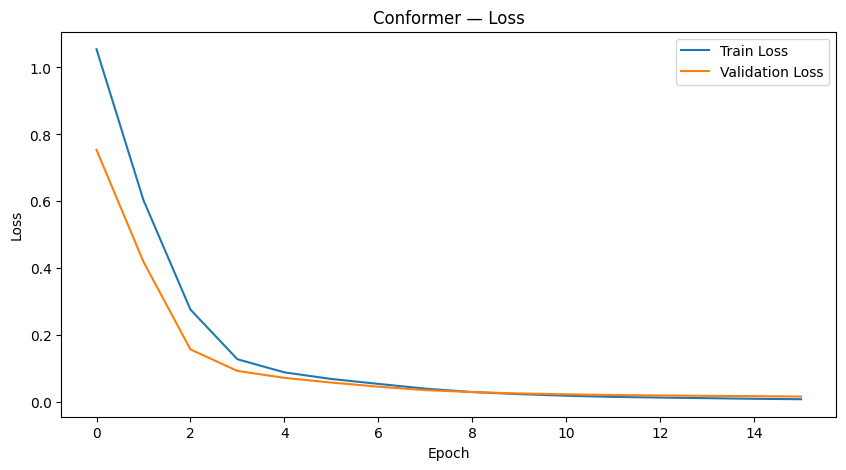

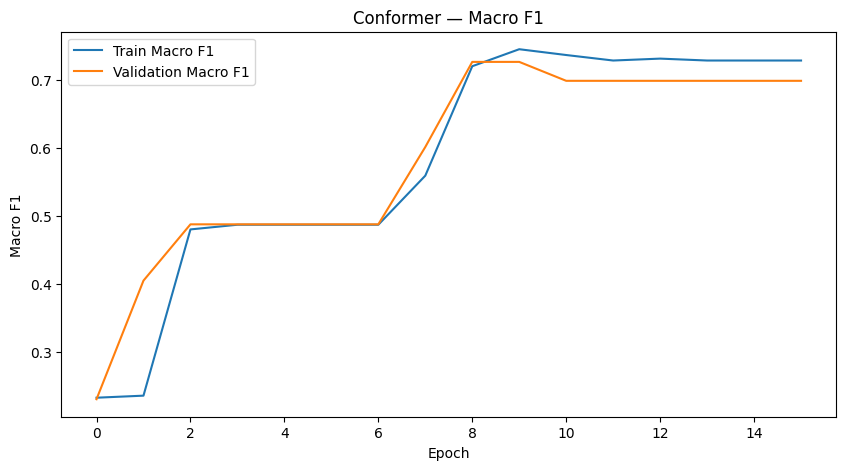

In [22]:
plt.figure(figsize=(10, 5))
plt.plot(
    history["train_loss"],
    label="Train Loss",
)
plt.plot(
    history["val_loss"],
    label="Validation Loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Conformer — Loss")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(
    history["train_f1"],
    label="Train Macro F1",
)
plt.plot(
    history["val_f1"],
    label="Validation Macro F1",
)
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("Conformer — Macro F1")
plt.legend()
plt.show()


## 8. Evaluation

In [23]:
test_loss, test_acc, test_f1, y_true, y_pred = run_epoch(
    model,
    test_loader,
    criterion,
    device,
)

test_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

test_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

test_balanced_acc = balanced_accuracy_score(
    y_true,
    y_pred,
)

print("=" * 50)
print("FINAL TEST RESULT — TABULAR CONFORMER")
print("=" * 50)
print(f"Accuracy          : {test_acc:.4f}")
print(f"Macro Precision   : {test_precision:.4f}")
print(f"Macro Recall      : {test_recall:.4f}")
print(f"Macro F1          : {test_f1:.4f}")
print(f"Balanced Accuracy : {test_balanced_acc:.4f}")
print(f"Test Loss         : {test_loss:.4f}")


FINAL TEST RESULT — TABULAR CONFORMER
Accuracy          : 0.9984
Macro Precision   : 0.7471
Macro Recall      : 0.7500
Macro F1          : 0.7485
Balanced Accuracy : 0.7500
Test Loss         : 0.0219


In [24]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=[
            TARGET_NAMES[i]
            for i in range(4)
        ],
        zero_division=0,
    )
)


                            precision    recall  f1-score   support

Sehat / Tidak Ada Indikasi       1.00      1.00      1.00       531
Jantung dan Pembuluh Darah       1.00      1.00      1.00         8
      Spes. Penyakit Dalam       0.99      1.00      0.99        84
           Spes. Paru-Paru       0.00      0.00      0.00         1

                  accuracy                           1.00       624
                 macro avg       0.75      0.75      0.75       624
              weighted avg       1.00      1.00      1.00       624



### Confusion Matrix

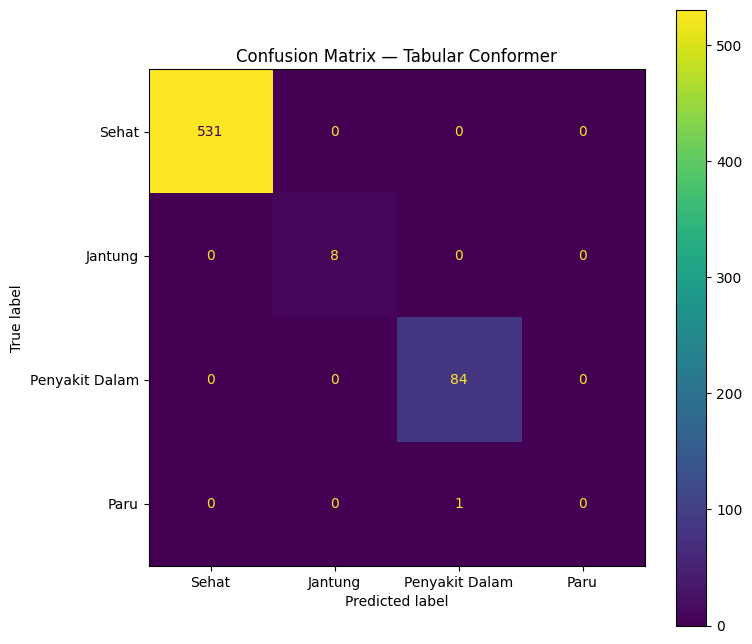

In [25]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
)

fig, ax = plt.subplots(
    figsize=(8, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Sehat",
        "Jantung",
        "Penyakit Dalam",
        "Paru",
    ],
)

disp.plot(
    ax=ax,
    values_format="d",
)

plt.title(
    "Confusion Matrix — Tabular Conformer"
)
plt.show()


## 9. Single Patient Prediction

In [26]:
model.eval()

sample_idx = 0

sample = X_test_scaled[sample_idx]
sample_tensor = torch.tensor(
    sample,
    dtype=torch.float32,
).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(sample_tensor)
    probabilities = torch.softmax(
        logits,
        dim=1,
    )[0].cpu().numpy()

prediction = int(
    probabilities.argmax()
)

print("Predicted class:")
print(
    f"{prediction} — "
    f"{TARGET_NAMES[prediction]}"
)

print("\nProbabilities:")
for class_id, prob in enumerate(probabilities):
    print(
        f"{class_id} — "
        f"{TARGET_NAMES[class_id]}: "
        f"{prob:.4f}"
    )


Predicted class:
0 — Sehat / Tidak Ada Indikasi

Probabilities:
0 — Sehat / Tidak Ada Indikasi: 0.9937
1 — Jantung dan Pembuluh Darah: 0.0029
2 — Spes. Penyakit Dalam: 0.0014
3 — Spes. Paru-Paru: 0.0020


## NOTE: Prototype Checkpoint

Jika notebook sampai sini tanpa `NaN` dan menghasilkan:

```text
[✓] Dataset terbaca
[✓] Target 4 kelas
[✓] Split stratified
[✓] Scaling train-only
[✓] Feature tokens terbentuk
[✓] Forward pass
[✓] Training
[✓] Validation
[✓] Test prediction
[✓] Classification report
[✓] Confusion matrix
```

maka prototype Conformer sudah **feasible untuk dilanjutkan**.

Tahap berikutnya baru kita evaluasi apakah representasi/tokenization dan arsitektur Conformer ini perlu dibandingkan dengan Random Forest/XGBoost, bukan langsung melakukan tuning besar.

## 10. Save Model & Preprocessing

Model dan preprocessing disimpan agar dapat langsung dipindahkan ke VPS/backend. File yang disimpan mencakup bobot Conformer, scaler, feature order, target mapping, dan konfigurasi model.


In [27]:
from pathlib import Path
import json
import joblib

MODEL_DIR = Path('artifacts')
MODEL_DIR.mkdir(exist_ok=True)

torch.save(model.state_dict(), MODEL_DIR / 'conformer_model.pth')
joblib.dump(scaler, MODEL_DIR / 'scaler.pkl')

config = {
    'feature_order': FEATURE_ORDER,
    'target_names': TARGET_NAMES,
    'num_features': NUM_FEATURES,
    'num_classes': NUM_CLASSES,
    'd_model': 64,
    'num_heads': 4,
    'num_layers': 2,
    'ffn_dim': 128,
    'conv_kernel_size': 3,
    'dropout': 0.1,
}
with open(MODEL_DIR / 'config.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print('Saved artifacts:')
for path in sorted(MODEL_DIR.iterdir()):
    print(path)


Saved artifacts:
artifacts/config.json
artifacts/conformer_model.pth
artifacts/scaler.pkl


## 11. Explainable AI — SHAP

### Tujuan XAI

Pada tahap ini kita menjelaskan **prediksi Conformer yang sudah dilatih**, bukan melatih ulang model.

SHAP digunakan untuk menjawab:

> Fitur apa yang paling berkontribusi terhadap probabilitas setiap kelas pada model?

Interpretasi SHAP di sini adalah **kontribusi fitur terhadap output model**, bukan hubungan kausal dan bukan diagnosis medis.

Flow:

```text
Trained Conformer
       ↓
Prediction Probability
       ↓
SHAP
       ↓
Global Feature Importance
       ↓
Local Explanation
```

In [28]:
import shap
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)


SHAP version: 0.54.1


### Fungsi prediction untuk SHAP

SHAP membutuhkan fungsi yang menerima data tabular `(n_samples, n_features)` dan mengembalikan probabilitas 4 kelas.

Kita tetap menggunakan `FEATURE_ORDER` yang sama dengan saat training.

In [29]:
def predict_proba_shap(X_numpy):
    X_numpy = np.asarray(X_numpy, dtype=np.float32)

    X_tensor = torch.tensor(
        X_numpy,
        dtype=torch.float32,
        device=device,
    )

    model.eval()

    with torch.no_grad():
        logits = model(X_tensor)
        probabilities = torch.softmax(
            logits,
            dim=1,
        )

    return probabilities.detach().cpu().numpy()


# Sanity check
proba_check = predict_proba_shap(
    X_test_scaled[:5]
)

print("Probability shape:", proba_check.shape)
print("Row sums:", proba_check.sum(axis=1))
print(pd.DataFrame(
    proba_check,
    columns=[TARGET_NAMES[i] for i in range(NUM_CLASSES)]
))

Probability shape: (5, 4)
Row sums: [0.99999994 1.0000001  1.         0.99999994 0.99999994]
   Sehat / Tidak Ada Indikasi  Jantung dan Pembuluh Darah  \
0                    0.993689                    0.002916   
1                    0.993893                    0.002826   
2                    0.992408                    0.003363   
3                    0.993918                    0.002810   
4                    0.993727                    0.002913   

   Spes. Penyakit Dalam  Spes. Paru-Paru  
0              0.001363         0.002032  
1              0.001354         0.001927  
2              0.002044         0.002185  
3              0.001328         0.001944  
4              0.001313         0.002048  


### Background dataset

Untuk SHAP, background diambil dari **training set**, bukan test set.

Kita gunakan subset agar komputasi tetap ringan pada prototype.

In [30]:
SHAP_BACKGROUND_SIZE = min(100, len(X_train_scaled))

background_rng = np.random.default_rng(SEED)

background_indices = background_rng.choice(
    len(X_train_scaled),
    size=SHAP_BACKGROUND_SIZE,
    replace=False,
)

X_background = X_train_scaled[
    background_indices
]

print("SHAP background shape:", X_background.shape)

SHAP background shape: (100, 13)


### SHAP explainer

Karena model kita adalah custom PyTorch Conformer, untuk prototype kita gunakan **model-agnostic SHAP**.

Ini lebih sederhana dan tidak bergantung pada detail internal autograd model.

Untuk 13 fitur, `PermutationExplainer` masih cukup masuk akal untuk prototype.

In [31]:
masker = shap.maskers.Independent(
    X_background
)

explainer = shap.Explainer(
    predict_proba_shap,
    masker,
    algorithm="permutation",
    seed=42,
)

print("SHAP explainer:", type(explainer).__name__)

SHAP explainer: PermutationExplainer


### Hitung SHAP values

Agar notebook tetap ringan, kita jelaskan sebagian test set terlebih dahulu.

Jumlah sample dapat dinaikkan setelah pipeline berhasil.

In [32]:
SHAP_SAMPLE_SIZE = min(50, len(X_test_scaled))

X_shap = X_test_scaled[
    :SHAP_SAMPLE_SIZE
]

shap_result = explainer(
    X_shap,
    max_evals=270,
)

print("SHAP values shape:", shap_result.values.shape)
print("Expected: (samples, features, classes)")

PermutationExplainer explainer: 51it [04:27,  5.46s/it]

SHAP values shape: (50, 13, 4)
Expected: (samples, features, classes)


### Rapikan output SHAP

Format SHAP dapat sedikit berbeda antar-versi library. Cell berikut menormalkan output menjadi:

```text
(samples, features, classes)
```

In [33]:
shap_values = np.asarray(
    shap_result.values
)

print("Raw SHAP shape:", shap_values.shape)

if shap_values.ndim == 3:
    # Format modern SHAP:
    # (samples, features, outputs)
    if shap_values.shape[1] == len(FEATURE_ORDER):
        shap_values_3d = shap_values
    # Fallback apabila library mengembalikan
    # (samples, outputs, features)
    elif shap_values.shape[2] == len(FEATURE_ORDER):
        shap_values_3d = np.transpose(
            shap_values,
            (0, 2, 1),
        )
    else:
        raise ValueError(
            f"Format SHAP tidak dikenali: {shap_values.shape}"
        )

elif shap_values.ndim == 2:
    # Single-output fallback
    shap_values_3d = shap_values[:, :, None]

else:
    raise ValueError(
        f"Jumlah dimensi SHAP tidak didukung: {shap_values.ndim}"
    )

print(
    "Normalized SHAP shape:",
    shap_values_3d.shape,
)

Raw SHAP shape: (50, 13, 4)
Normalized SHAP shape: (50, 13, 4)


# Global Explanation

### Global feature importance

Kita hitung:

```text
mean(|SHAP|)
```

di seluruh sample yang dijelaskan.

Ini menunjukkan fitur mana yang paling banyak digunakan model untuk membedakan kelas, **bukan fitur yang secara medis menyebabkan penyakit**.

In [34]:
global_importance = []

for class_id in range(NUM_CLASSES):
    mean_abs_shap = np.mean(
        np.abs(
            shap_values_3d[:, :, class_id]
        ),
        axis=0,
    )

    class_df = pd.DataFrame({
        "Feature": FEATURE_ORDER,
        "Mean |SHAP|": mean_abs_shap,
    }).sort_values(
        "Mean |SHAP|",
        ascending=False,
    )

    class_df["Class"] = TARGET_NAMES[class_id]

    global_importance.append(
        class_df
    )

global_importance_df = pd.concat(
    global_importance,
    ignore_index=True,
)

print(global_importance_df)

              Feature  Mean |SHAP|                       Class
0          UMUR_TAHUN     0.182949  Sehat / Tidak Ada Indikasi
1       JENIS_KELAMIN     0.047155  Sehat / Tidak Ada Indikasi
2                 fbs     0.022788  Sehat / Tidak Ada Indikasi
3                 hgb     0.003260  Sehat / Tidak Ada Indikasi
4           creatinin     0.002225  Sehat / Tidak Ada Indikasi
5           lymfosit%     0.001995  Sehat / Tidak Ada Indikasi
6                 rbs     0.001823  Sehat / Tidak Ada Indikasi
7                 mcv     0.001566  Sehat / Tidak Ada Indikasi
8   cholesterol total     0.001235  Sehat / Tidak Ada Indikasi
9                 mch     0.001081  Sehat / Tidak Ada Indikasi
10              ureum     0.001009  Sehat / Tidak Ada Indikasi
11                wbc     0.000989  Sehat / Tidak Ada Indikasi
12               mchc     0.000119  Sehat / Tidak Ada Indikasi
13                mcv     0.015113  Jantung dan Pembuluh Darah
14         UMUR_TAHUN     0.008199  Jantung dan Pembulu

### Plot global importance per class

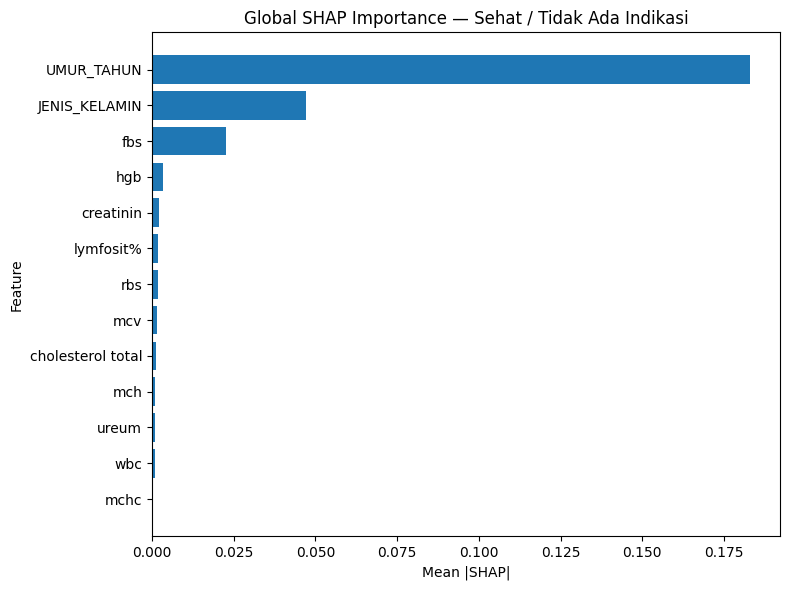

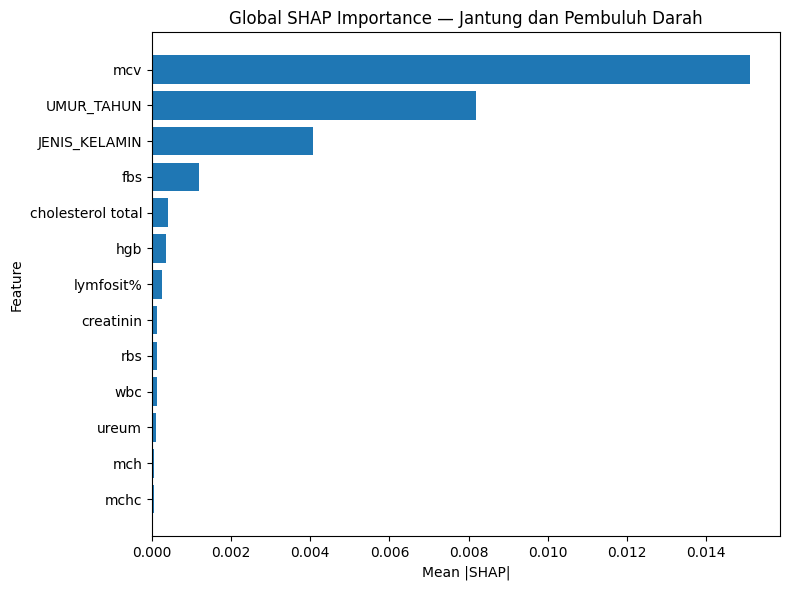

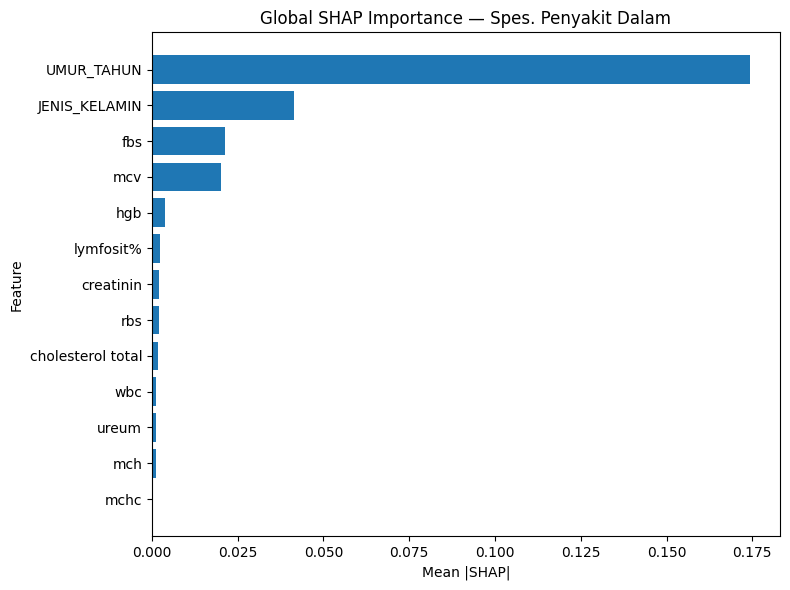

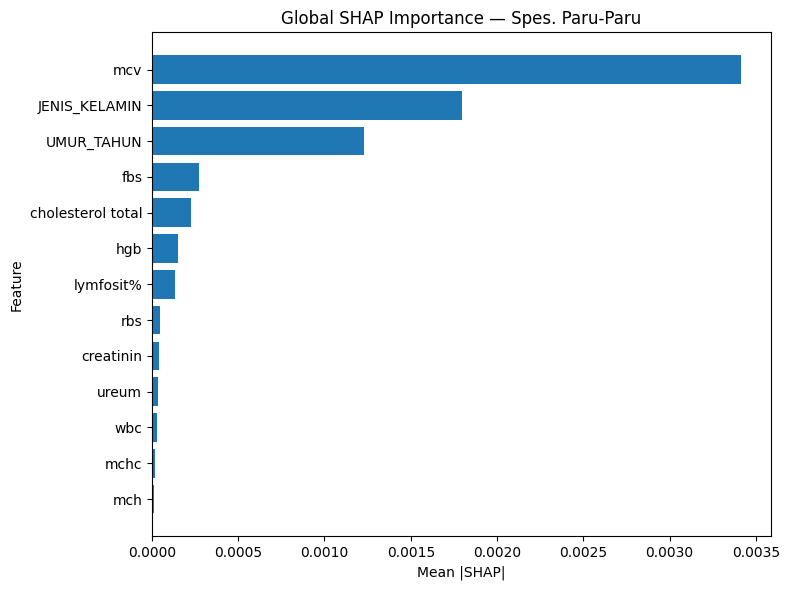

In [35]:
for class_id in range(NUM_CLASSES):

    class_df = (
        global_importance_df[
            global_importance_df["Class"]
            == TARGET_NAMES[class_id]
        ]
        .sort_values(
            "Mean |SHAP|",
            ascending=True,
        )
    )

    plt.figure(figsize=(8, 6))

    plt.barh(
        class_df["Feature"],
        class_df["Mean |SHAP|"],
    )

    plt.xlabel("Mean |SHAP|")
    plt.ylabel("Feature")
    plt.title(
        "Global SHAP Importance — "
        + TARGET_NAMES[class_id]
    )

    plt.tight_layout()
    plt.show()

# Local Explanation

### Jelaskan satu pasien

Untuk demo XAI, kita ambil satu pasien dari test set.

Kita gunakan **predicted class** pasien tersebut, kemudian melihat fitur yang mendorong output model ke kelas tersebut.

In [36]:
sample_id = 0

sample_x = X_test_scaled[
    sample_id:sample_id + 1
]

sample_prob = predict_proba_shap(
    sample_x
)[0]

predicted_class = int(
    np.argmax(sample_prob)
)

print("Predicted class:")
print(
    predicted_class,
    "—",
    TARGET_NAMES[predicted_class],
)

print("\nProbabilities:")

for class_id, probability in enumerate(
    sample_prob
):
    print(
        f"{class_id} — "
        f"{TARGET_NAMES[class_id]}: "
        f"{probability:.4f}"
    )

Predicted class:
0 — Sehat / Tidak Ada Indikasi

Probabilities:
0 — Sehat / Tidak Ada Indikasi: 0.9937
1 — Jantung dan Pembuluh Darah: 0.0029
2 — Spes. Penyakit Dalam: 0.0014
3 — Spes. Paru-Paru: 0.0020


### Feature contribution untuk predicted class

In [37]:
local_shap = shap_values_3d[
    sample_id,
    :,
    predicted_class,
]

local_df = pd.DataFrame({
    "Feature": FEATURE_ORDER,
    "Scaled Value": sample_x[0],
    "SHAP": local_shap,
})

local_df["Abs SHAP"] = local_df["SHAP"].abs()

local_df = local_df.sort_values(
    "Abs SHAP",
    ascending=False,
)

print(local_df)

              Feature  Scaled Value      SHAP  Abs SHAP
1          UMUR_TAHUN     -0.405649  0.102877  0.102877
0       JENIS_KELAMIN      0.393177  0.013133  0.013133
4                 fbs     -0.104146  0.004713  0.004713
9                mchc     -3.737106  0.002693  0.002693
7           lymfosit%     -0.774870  0.001337  0.001337
2   cholesterol total      1.124326  0.001042  0.001042
3           creatinin     -0.276403  0.000788  0.000788
5                 rbs     -0.195264  0.000771  0.000771
8                 mch     -0.283486  0.000691  0.000691
11              ureum     -0.376126  0.000345  0.000345
12                wbc      1.109357  0.000242  0.000242
6                 hgb     -0.436279 -0.000192  0.000192
10                mcv     -0.257610 -0.000066  0.000066


### Plot local explanation

Interpretasi sederhana:

- SHAP positif → mendorong output model ke kelas yang sedang dijelaskan.
- SHAP negatif → mendorong output model menjauh dari kelas tersebut.
- Besarnya SHAP → seberapa kuat kontribusi fitur terhadap output model.

**Ini bukan hubungan sebab-akibat medis.**

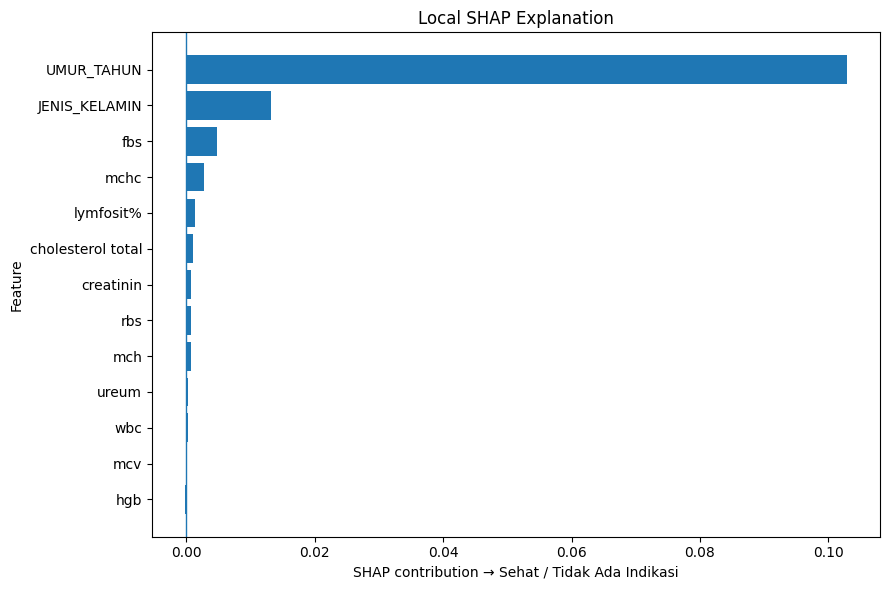

In [38]:
plot_df = local_df.sort_values(
    "SHAP"
)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["SHAP"],
)

plt.axvline(
    0,
    linewidth=1,
)

plt.xlabel(
    f"SHAP contribution → "
    f"{TARGET_NAMES[predicted_class]}"
)

plt.ylabel("Feature")

plt.title(
    "Local SHAP Explanation"
)

plt.tight_layout()
plt.show()

# SHAP Summary

### Ringkasan XAI

Setelah cell-cell di atas berhasil, kita memiliki dua jenis output:

**Global XAI**

```text
Feature
   ↓
Mean absolute SHAP
   ↓
Feature importance per class
```

**Local XAI**

```text
1 pasien
   ↓
Predicted class
   ↓
SHAP contribution tiap feature
```

Output ini nantinya dapat disimpan sebagai JSON untuk backend/web demo dan diberikan ke LLM sebagai data terstruktur.

In [39]:
# Contoh struktur data yang nantinya dapat dikirim ke backend/LLM.

explanation_payload = {
    "prediction": {
        "class_id": predicted_class,
        "class_name": TARGET_NAMES[predicted_class],
        "probabilities": {
            TARGET_NAMES[i]: float(sample_prob[i])
            for i in range(NUM_CLASSES)
        },
    },
    "feature_contributions": [
        {
            "feature": row["Feature"],
            "value_scaled": float(row["Scaled Value"]),
            "shap": float(row["SHAP"]),
        }
        for _, row in local_df.iterrows()
    ],
}

print(json.dumps(
    explanation_payload,
    indent=2,
    ensure_ascii=False,
))

{
  "prediction": {
    "class_id": 0,
    "class_name": "Sehat / Tidak Ada Indikasi",
    "probabilities": {
      "Sehat / Tidak Ada Indikasi": 0.9936890602111816,
      "Jantung dan Pembuluh Darah": 0.0029164960142225027,
      "Spes. Penyakit Dalam": 0.0013626754516735673,
      "Spes. Paru-Paru": 0.0020316899754107
    }
  },
  "feature_contributions": [
    {
      "feature": "UMUR_TAHUN",
      "value_scaled": -0.40564852952957153,
      "shap": 0.10287721296586094
    },
    {
      "feature": "JENIS_KELAMIN",
      "value_scaled": 0.39317721128463745,
      "shap": 0.013133014988066866
    },
    {
      "feature": "fbs",
      "value_scaled": -0.10414626449346542,
      "shap": 0.004713423239940307
    },
    {
      "feature": "mchc",
      "value_scaled": -3.73710560798645,
      "shap": 0.0026927545180078505
    },
    {
      "feature": "lymfosit%",
      "value_scaled": -0.7748698592185974,
      "shap": 0.0013373562729684708
    },
    {
      "feature": "cholesterol to

## 12. Export Artifacts

Folder `artifacts/` dapat langsung dipindahkan ke backend/VPS.

In [40]:
import shutil

zip_path = shutil.make_archive(
    'conformer_artifacts',
    'zip',
    'artifacts'
)
print('Archive:', zip_path)


Archive: /content/conformer_artifacts.zip
